# 📊 Caption Evaluation — Traditional NLP Metrics


## ⚙️ Configuration


In [ ]:
# ============================================================
# CONFIGURATION
# ============================================================

BASE_PATH = "/content/drive/MyDrive/Benchmarked data"

# Ground truth directory (single CSV file, column: summary_gt)
GT_FOLDER = "summary_ground_truth"
GT_COL    = "summary_gt"

# Prediction column in pred_caption_summary.csv files
PRED_COL  = "summary_pred"   # change if column name differs

# Evaluated datasets — adjust list as needed
DATASET_CONFIGS = [
    # {
    #     "name":   "DAM",
    #     "folder": "DAM_output/PACO",
    # },
    # Uncomment to evaluate additional models:
    {"name": "GPT4Roi", "folder": "GPT4Roi_output/PACO"},
    {"name": "Shikra",  "folder": "Shikra_output/PACO"},
    {"name": "VIP-LLAVA", "folder": "Vip_Llava_output/PACO"},
]

# Results output file path
OUTPUT_CSV = "/content/metrics_results.csv"


## 📦 Install Dependencies


In [ ]:
!pip install -q pycocoevalcap pycocotools
!apt-get update -y > /dev/null
!apt-get install -y openjdk-11-jre-headless > /dev/null
!update-alternatives --set java /usr/lib/jvm/java-11-openjdk-amd64/bin/java
# pycocoevalcap provides: BLEU, METEOR, ROUGE_L, CIDEr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 10.5 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/java to provide /usr/bin/java (java) in manual mode


## 🔗 Mount Google Drive (Colab Optional)


In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 📥 Imports & Scorer Setup


In [ ]:
import os
import glob
import re
import pandas as pd
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.meteor.meteor import Meteor
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.spice.spice import Spice


SCORERS = [
    (Bleu(4), ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4"]),
    (Meteor(), "METEOR"),
    (Rouge(),  "ROUGE_L"),
    (Cider(),  "CIDEr"),
    (Spice(), "SPICE")
]
print("✅ Imports OK")


Progress: 384.5M / 384.5M (100.0%)
Extracting stanford-corenlp-3.6.0 ...
Done.
✅ Imports OK


## 📂 Load Ground Truth References


In [ ]:
import os
import pandas as pd

gt_folder = os.path.join(BASE_PATH, GT_FOLDER)
gt_files  = [f for f in os.listdir(gt_folder) if f.endswith(".csv")]

if not gt_files:
    raise FileNotFoundError(f"No CSV files found in: {gt_folder}")

gt_path = os.path.join(gt_folder, gt_files[0])
df_gt   = pd.read_csv(gt_path)
print(f"✅ Loaded ground truth: {gt_files[0]}  ({len(df_gt):,} rows)")
print(f"   Columns: {list(df_gt.columns)}")

# Verify GT_COL exists in dataframe
assert GT_COL in df_gt.columns, f"Column '{GT_COL}' does not exist in GT file! Available columns: {list(df_gt.columns)}"
print(f"   GT Column: '{GT_COL}'")
print(df_gt[[GT_COL]].head(3))


✅ Loaded ground truth: ground_truth_summary_0_to_1500_pred_caption_summary.csv  (1,500 rows)
   Columns: ['dataset_name', 'ann_id', 'img_id', 'image_path', 'mask_size', 'category', 'caption', 'mask_rle_counts', 'bboxes', 'attributes', 'parts', 'image_noise_type', 'image_severity', 'bbox_noise_type', 'bbox_severity', 'mask_noise_type', 'mask_severity', 'pred_keyword', 'pred_phrase', 'pred_detailed', 'dlc_frequency', 'dlc_obj_size', 'dlc_iscrowd', 'dlc_isfake', 'dlc_isreflected', 'summary_gt']
   GT Column: 'summary_gt'
                                          summary_gt
0  Trash can label with bold red "LICENSE ONLY" a...
1                            Silver circular eyelet.
2  Rounded metallic kettle lid with shiny, reflec...


## 🛠️ Metric Calculation Helpers


In [ ]:
# Tokenizer import
from pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer

def build_coco_dicts(gt_series, pred_series):
    """
    Format predictions for PTBTokenizer input
    """
    gts, res = {}, {}
    for i, (gt_text, pred_text) in enumerate(zip(gt_series, pred_series)):
        # Wrap in dictionary format expected by PTBTokenizer with 'caption' key
        gts[i] = [{'caption': str(gt_text)}]
        res[i] = [{'caption': str(pred_text)}]
    return gts, res

def compute_metrics(gts: dict, res: dict) -> dict:
    # 1. Pre-tokenize text (lowercase, punctuation splitting)
    tokenizer = PTBTokenizer()
    gts_tok = tokenizer.tokenize(gts)
    res_tok = tokenizer.tokenize(res)
    # Tokenize returns {id: ["normalized_caption"]} for downstream scorers

    # 2. Compute metric scores using tokenized dictionaries
    scorers = [
        (Bleu(4), ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4"]),
        (Meteor(), "METEOR"),
        (Rouge(),  "ROUGE_L"),
        (Cider(),  "CIDEr"),
        (Spice(), "SPICE")
    ]
    results = {}
    for scorer, method in scorers:
        try:
            # Evaluate with gts_tok and res_tok
            score, _ = scorer.compute_score(gts_tok, res_tok)
            if isinstance(method, list):
                for m, s in zip(method, score):
                    results[m] = round(float(s), 6)
            else:
                results[method] = round(float(score), 6)
        except Exception as e:
            metric_names = method if isinstance(method, list) else [method]
            for m in metric_names:
                results[m] = None
            print(f"  ⚠️  {metric_names} error: {e}")
    return results


def infer_noise_info(filename: str):
    """
    Parse filename to extract noise_type and noise_level.

    Example:
        vip_llava_PACO_bbox_clean_0_to_1500_pred_caption_summary.csv
            -> noise_type=clean, noise_level=None

        vip_llava_PACO_img_noise_brightness_level_1_bbox_0_to_1500_pred_caption_summary.csv
            -> noise_type=brightness, noise_level=1

        vip_llava_PACO_bbox_noise_blur_level_2_0_to_1500_pred_caption_summary.csv
            -> noise_type=blur, noise_level=2
    """
    name = os.path.splitext(filename)[0]

    if "clean" in name:
        return "clean", None

    # img_noise_<type>_level_<N>
    m = re.search(r"img_noise_([a-zA-Z_]+?)_level_(\d+)", name)
    if m:
        return m.group(1), int(m.group(2))

    # bbox_noise_<type>_level_<N>
    m = re.search(r"bbox_noise_([a-zA-Z_]+?)_level_(\d+)", name)
    if m:
        return m.group(1), int(m.group(2))

    return "unknown", None


def eval_csv(csv_path: str, df_gt: pd.DataFrame, pred_col: str = PRED_COL) -> dict | None:
    """
    Read a prediction CSV file and compute evaluation metrics against df_gt.
    Returns results dict, or None on error.
    """
    try:
        df_pred = pd.read_csv(csv_path)
    except Exception as e:
        print(f"  ❌ Failed to read {csv_path}: {e}")
        return None

    # Auto-detect prediction column if not specified
    if pred_col not in df_pred.columns:
        # Priority: columns containing 'summary', then 'pred', fallback to 'caption'
        candidates_summary = [c for c in df_pred.columns if "summary" in c.lower()]
        candidates_pred    = [c for c in df_pred.columns if "pred" in c.lower() and "summary" not in c.lower()]
        candidates_caption = [c for c in df_pred.columns if c.lower() == "caption"]
        candidates = candidates_summary or candidates_pred or candidates_caption
        if candidates:
            pred_col_used = candidates[0]
            print(f"  ⚠️  Column '{pred_col}' not found; using '{pred_col_used}' as fallback.")
        else:
            print(f"  ❌ Prediction column not found in {csv_path}. Columns: {list(df_pred.columns)}")
            return None
    else:
        pred_col_used = pred_col

    # Align row counts and drop NaN entries
    n = min(len(df_gt), len(df_pred))
    gt_vals   = df_gt[GT_COL].iloc[:n].fillna("").astype(str)
    pred_vals = df_pred[pred_col_used].iloc[:n].fillna("").astype(str)

    # Drop completely empty caption pairs
    mask = (gt_vals.str.strip() != "") & (pred_vals.str.strip() != "")
    gt_vals   = gt_vals[mask].reset_index(drop=True)
    pred_vals = pred_vals[mask].reset_index(drop=True)

    if len(gt_vals) == 0:
        print(f"  ❌ No valid rows remaining after filtering NaNs.")
        return None

    gts, res = build_coco_dicts(gt_vals, pred_vals)
    return compute_metrics(gts, res)


## 🔍 Scan and Compute Metrics across Files


In [ ]:
all_results = []

for cfg in DATASET_CONFIGS:
    dataset_name = cfg["name"]
    paco_folder  = os.path.join(BASE_PATH, cfg["folder"])
    print(f"\n{'='*60}")
    print(f"📁 Dataset: {dataset_name}  |  Folder: {paco_folder}")
    print('='*60)

    # ── 1. CLEAN BASELINE ───────────────────────────────────────────
    clean_files = [
        f for f in os.listdir(paco_folder)
        if f.endswith("_pred_caption_summary.csv")
    ]
    print(f"\n[CLEAN] Found {len(clean_files)} file(s)")

    for fname in sorted(clean_files):
        fpath = os.path.join(paco_folder, fname)
        noise_type, noise_level = infer_noise_info(fname)
        print(f"  → {fname}")
        metrics = eval_csv(fpath, df_gt)
        if metrics:
            row = {
                "dataset":     dataset_name,
                "noise_category": "clean",
                "noise_type":  noise_type,
                "noise_level": noise_level,
                "file":        fname,
            }
            row.update(metrics)
            all_results.append(row)
            print(f"     BLEU-4={metrics['Bleu_4']:.4f}  METEOR={metrics['METEOR']:.4f}  ROUGE_L={metrics['ROUGE_L']:.4f}  CIDEr={metrics['CIDEr']:.4f} SPICE={metrics['SPICE']:.4f}")

    # ── 2. IMAGE NOISE ──────────────────────────────────────────────
    img_folder = os.path.join(paco_folder, "image")
    if os.path.isdir(img_folder):
        # Filter files ending with _pred_caption_summary.csv
        img_files = [f for f in os.listdir(img_folder) if f.endswith("_pred_caption_summary.csv")]
        print(f"\n[IMAGE noise] Found {len(img_files)} file(s)")
        for fname in sorted(img_files):
            fpath = os.path.join(img_folder, fname)
            noise_type, noise_level = infer_noise_info(fname)
            print(f"  → {fname}")
            metrics = eval_csv(fpath, df_gt)
            if metrics:
                row = {
                    "dataset":        dataset_name,
                    "noise_category": "image_noise",
                    "noise_type":     noise_type,
                    "noise_level":    noise_level,
                    "file":           fname,
                }
                row.update(metrics)
                all_results.append(row)
                print(f"     BLEU-4={metrics['Bleu_4']:.4f}  METEOR={metrics['METEOR']:.4f}  ROUGE_L={metrics['ROUGE_L']:.4f}  CIDEr={metrics['CIDEr']:.4f} SPICE={metrics['SPICE']:.4f}")
    else:
        print(f"\n[IMAGE noise] Directory does not exist: {img_folder}")

    # ── 3. BBOX NOISE ───────────────────────────────────────────────
    bbox_folder = os.path.join(paco_folder, "bbox")
    if os.path.isdir(bbox_folder):
        # Filter files ending with _pred_caption_summary.csv
        bbox_files = [f for f in os.listdir(bbox_folder) if f.endswith("_pred_caption_summary.csv")]
        print(f"\n[BBOX noise] Found {len(bbox_files)} file(s)")
        for fname in sorted(bbox_files):
            fpath = os.path.join(bbox_folder, fname)
            noise_type, noise_level = infer_noise_info(fname)
            print(f"  → {fname}")
            metrics = eval_csv(fpath, df_gt)
            if metrics:
                row = {
                    "dataset":        dataset_name,
                    "noise_category": "bbox_noise",
                    "noise_type":     noise_type,
                    "noise_level":    noise_level,
                    "file":           fname,
                }
                row.update(metrics)
                all_results.append(row)
                print(f"     BLEU-4={metrics['Bleu_4']:.4f}  METEOR={metrics['METEOR']:.4f}  ROUGE_L={metrics['ROUGE_L']:.4f}  CIDEr={metrics['CIDEr']:.4f} SPICE={metrics['SPICE']:.4f}")
    else:
        print(f"\n[BBOX noise] Directory does not exist: {bbox_folder}")

print(f"\n✅ Done! Total evaluated files: {len(all_results)}")



📁 Dataset: GPT4Roi  |  Folder: /content/drive/MyDrive/Benchmarked data/GPT4Roi_output/PACO

[CLEAN] Found 1 file(s)
  → gpt4roi_PACO_clean_bbox_0_to_1500_pred_caption_summary.csv
{'testlen': 3681, 'reflen': 13344, 'guess': [3681, 2181, 790, 294], 'correct': [1180, 103, 11, 1]}
ratio: 0.2758543165467419
     BLEU-4=0.0021  METEOR=0.0456  ROUGE_L=0.1192  CIDEr=0.2574 SPICE=0.0576

[IMAGE noise] Found 15 file(s)
  → gpt4roi_PACO_img_noise_brightness_level_1_bbox_0_to_1500_pred_caption_summary_pred_caption_summary.csv
{'testlen': 3658, 'reflen': 13344, 'guess': [3658, 2158, 767, 283], 'correct': [1163, 106, 8, 0]}
ratio: 0.2741306954436245
     BLEU-4=0.0000  METEOR=0.0452  ROUGE_L=0.1189  CIDEr=0.2544 SPICE=0.0580
  → gpt4roi_PACO_img_noise_brightness_level_3_bbox_0_to_1500_pred_caption_summary_pred_caption_summary.csv
{'testlen': 3714, 'reflen': 13344, 'guess': [3714, 2214, 815, 287], 'correct': [1148, 94, 6, 0]}
ratio: 0.2783273381294755
     BLEU-4=0.0000  METEOR=0.0442  ROUGE_L=0.117

## 📊 Consolidated Results Summary


In [ ]:
df_results = pd.DataFrame(all_results)

METRIC_COLS = ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4", "METEOR", "ROUGE_L", "CIDEr", "SPICE"]
INFO_COLS   = ["dataset", "noise_category", "noise_type", "noise_level"]

# Round values for display
df_display = df_results[INFO_COLS + METRIC_COLS].copy()
for col in METRIC_COLS:
    df_display[col] = df_display[col].map(lambda x: f"{x:.4f}")

print(f"Total rows: {len(df_display)}")
display(df_display)


Total rows: 66


,dataset,noise_category,noise_type,noise_level,Bleu_1,Bleu_2,Bleu_3,Bleu_4,METEOR,ROUGE_L,CIDEr,SPICE
0,GPT4Roi,clean,clean,NaN,0.0232,0.0089,0.0043,0.0021,0.0456,0.1192,0.2574,0.0576
1,GPT4Roi,image_noise,brightness,1.0,0.0225,0.0088,0.0039,0.0000,0.0452,0.1189,0.2544,0.0580
2,GPT4Roi,image_noise,brightness,3.0,0.0231,0.0086,0.0034,0.0000,0.0442,0.1175,0.2456,0.0572
3,GPT4Roi,image_noise,brightness,5.0,0.0205,0.0075,0.0027,0.0000,0.0420,0.1094,0.2254,0.0530
4,GPT4Roi,image_noise,contrast,1.0,0.0217,0.0080,0.0033,0.0000,0.0440,0.1170,0.2473,0.0574
...,...,...,...,...,...,...,...,...,...,...,...,...
61,VIP-LLAVA,bbox_noise,shift,3.0,0.0864,0.0352,0.0159,0.0071,0.0653,0.1625,0.3346,0.0780
62,VIP-LLAVA,bbox_noise,shift,5.0,0.0806,0.0322,0.0132,0.0044,0.0612,0.1553,0.3045,0.0734
63,VIP-LLAVA,bbox_noise,upscale,1.0,0.0889,0.0376,0.0159,0.0060,0.0686,0.1719,0.3546,0.0839
64,VIP-LLAVA,bbox_noise,upscale,3.0,0.0899,0.0365,0.0155,0.0070,0.0675,0.1708,0.3473,0.0833


## 💾 Save Results to CSV


In [ ]:
df_results.to_csv(OUTPUT_CSV, index=False)
print(f"✅ Results saved to: {OUTPUT_CSV}")

# Download file to local environment (Colab only)
try:
    from google.colab import files
    files.download(OUTPUT_CSV)
except Exception:
    print("(Not running in Google Colab — skipping download)")


✅ Results saved to: /content/metrics_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📈 Statistics by Noise Type


In [ ]:
METRIC_COLS = ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4", "METEOR", "ROUGE_L", "CIDEr", "SPICE"]

# Grouped mean by dataset and noise_category
summary = (
    df_results
    .groupby(["dataset", "noise_category"])[METRIC_COLS]
    .mean()
    .round(4)
    .reset_index()
)
print("=== Macro Average by Dataset + Noise Category ===")
display(summary)

# Grouped mean by dataset and noise_type
summary2 = (
    df_results
    .groupby(["dataset", "noise_category", "noise_type"])[METRIC_COLS]
    .mean()
    .round(4)
    .reset_index()
)
print("\n=== Detailed Average by Perturbation Type ===")
display(summary2)


=== Macro Average by Dataset + Noise Category ===


,dataset,noise_category,Bleu_1,Bleu_2,Bleu_3,Bleu_4,METEOR,ROUGE_L,CIDEr,SPICE
0,GPT4Roi,bbox_noise,0.0228,0.0085,0.0038,0.0010,0.0446,0.1166,0.2465,0.0581
1,GPT4Roi,clean,0.0232,0.0089,0.0043,0.0021,0.0456,0.1192,0.2574,0.0576
2,GPT4Roi,image_noise,0.0202,0.0076,0.0029,0.0000,0.0421,0.1105,0.2298,0.0546
3,Shikra,bbox_noise,0.0367,0.0143,0.0057,0.0028,0.0514,0.1306,0.2772,0.0719
4,Shikra,clean,0.0359,0.0142,0.0056,0.0033,0.0518,0.1317,0.2758,0.0736
5,Shikra,image_noise,0.0337,0.0131,0.0048,0.0016,0.0485,0.1242,0.2572,0.0684
6,VIP-LLAVA,bbox_noise,0.0873,0.0359,0.0153,0.0065,0.0661,0.1668,0.3387,0.0800
7,VIP-LLAVA,clean,0.0891,0.0367,0.0162,0.0076,0.0679,0.1721,0.3505,0.0816
8,VIP-LLAVA,image_noise,0.0770,0.0295,0.0123,0.0040,0.0593,0.1517,0.2943,0.0695



=== Detailed Average by Perturbation Type ===


,dataset,noise_category,noise_type,Bleu_1,Bleu_2,Bleu_3,Bleu_4,METEOR,ROUGE_L,CIDEr,SPICE
0,GPT4Roi,bbox_noise,shift,0.0203,0.0074,0.0036,0.0013,0.0422,0.1102,0.2324,0.0544
1,GPT4Roi,bbox_noise,upscale,0.0252,0.0096,0.0041,0.0007,0.0469,0.1231,0.2606,0.0618
2,GPT4Roi,clean,clean,0.0232,0.0089,0.0043,0.0021,0.0456,0.1192,0.2574,0.0576
3,GPT4Roi,image_noise,brightness,0.0220,0.0083,0.0033,0.0000,0.0438,0.1153,0.2418,0.0560
4,GPT4Roi,image_noise,contrast,0.0188,0.0066,0.0026,0.0000,0.0402,0.1065,0.2192,0.0514
5,GPT4Roi,image_noise,defocus_blur,0.0198,0.0075,0.0027,0.0000,0.0416,0.1089,0.2269,0.0542
6,GPT4Roi,image_noise,gaussian_noise,0.0192,0.0071,0.0029,0.0000,0.0410,0.1073,0.2210,0.0534
7,GPT4Roi,image_noise,jpeg_compression,0.0213,0.0083,0.0032,0.0000,0.0438,0.1148,0.2400,0.0577
8,Shikra,bbox_noise,shift,0.0356,0.0139,0.0057,0.0028,0.0503,0.1278,0.2719,0.0711
9,Shikra,bbox_noise,upscale,0.0377,0.0148,0.0057,0.0028,0.0525,0.1334,0.2825,0.0727


## 📈 Statistics by Noise Type


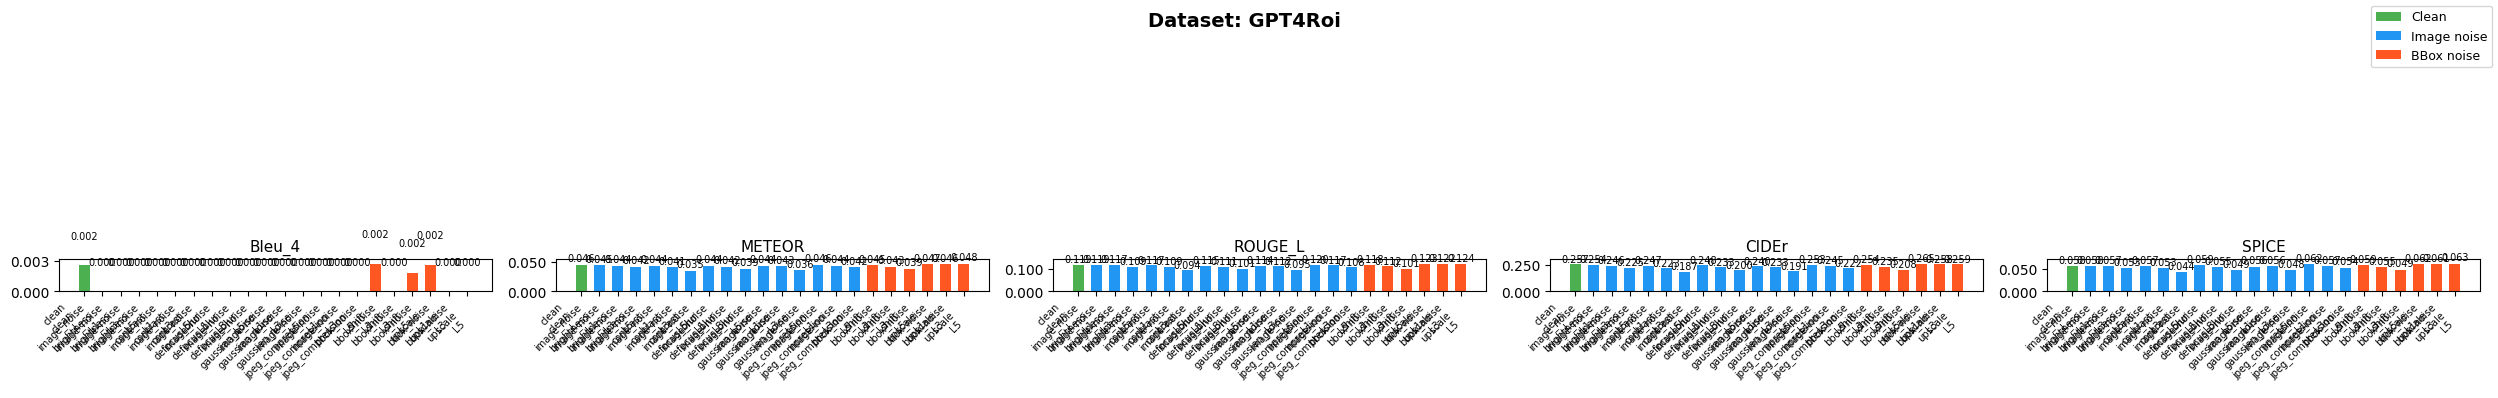

✅ Chart saved: /content/GPT4Roi_metrics.png


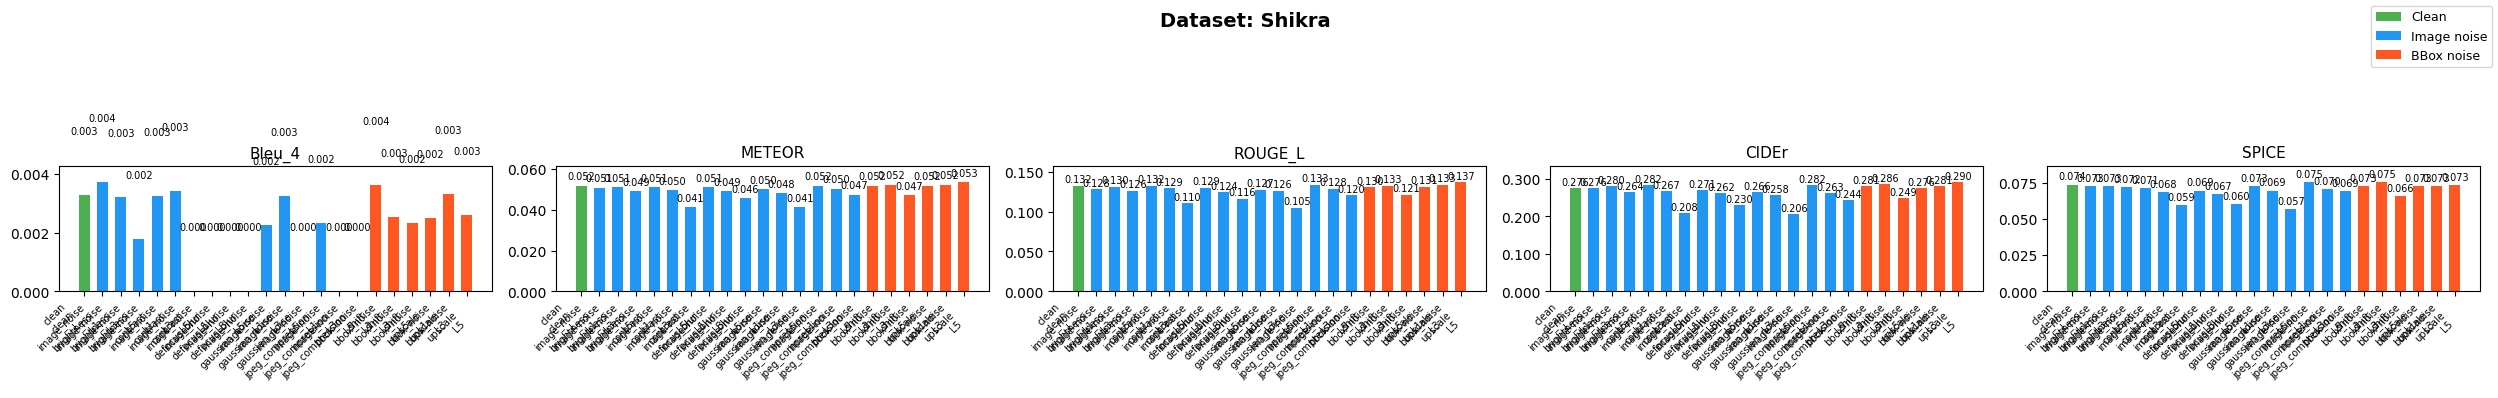

✅ Chart saved: /content/Shikra_metrics.png


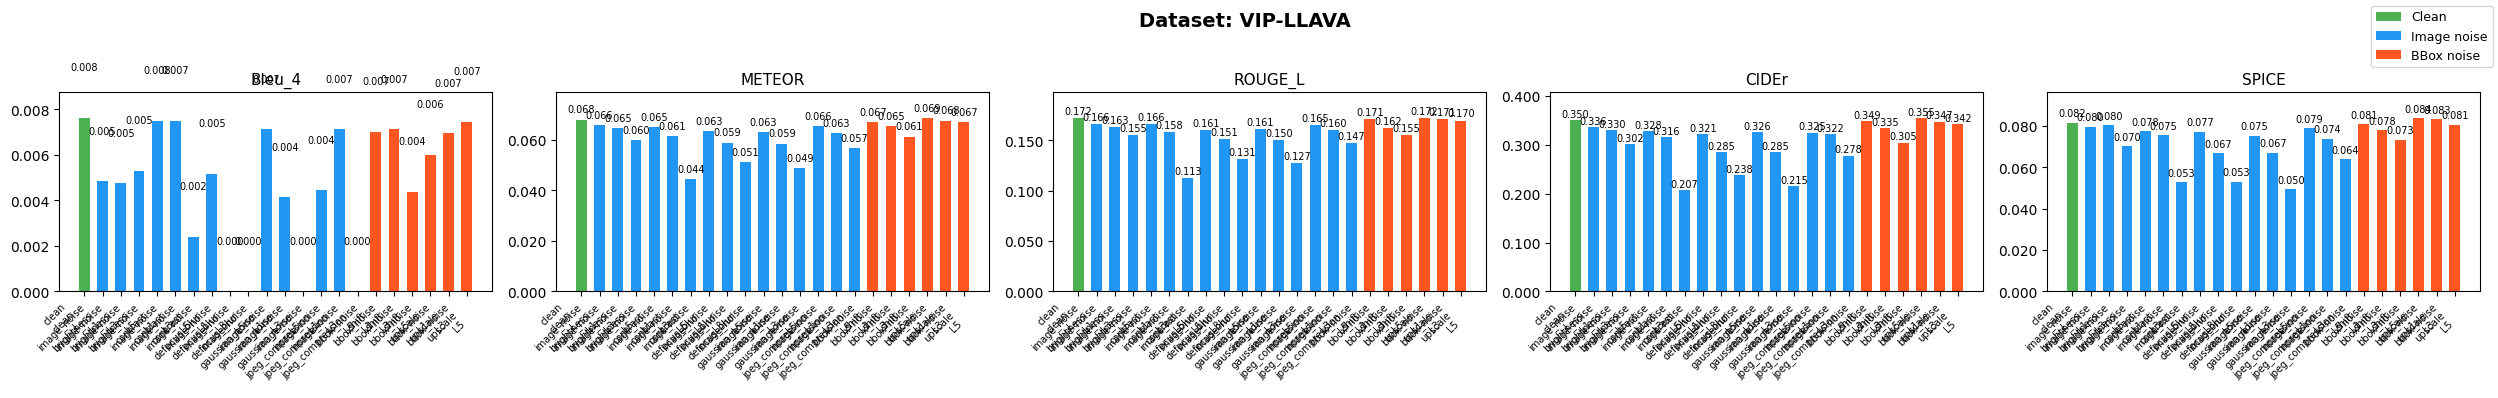

✅ Chart saved: /content/VIP-LLAVA_metrics.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

METRICS_TO_PLOT = ["Bleu_4", "METEOR", "ROUGE_L", "CIDEr", "SPICE"]

for dataset_name in df_results["dataset"].unique():
    df_ds = df_results[df_results["dataset"] == dataset_name].copy()

    # Sort order: clean first, then image_noise, then bbox_noise
    cat_order = {"clean": 0, "image_noise": 1, "bbox_noise": 2}
    df_ds["_cat_ord"] = df_ds["noise_category"].map(cat_order)
    df_ds = df_ds.sort_values(["_cat_ord", "noise_type", "noise_level"])
    labels = df_ds.apply(
        lambda r: f"{r['noise_category']}\n{r['noise_type']}\nL{int(r['noise_level']) if pd.notna(r['noise_level']) else '-'}",
        axis=1
    ).tolist()

    fig, axes = plt.subplots(1, len(METRICS_TO_PLOT), figsize=(5 * len(METRICS_TO_PLOT), 4))
    fig.suptitle(f"Dataset: {dataset_name}", fontsize=14, fontweight="bold")

    for ax, metric in zip(axes, METRICS_TO_PLOT):
        values = df_ds[metric].values
        colors = ["#4CAF50" if c == "clean" else "#2196F3" if c == "image_noise" else "#FF5722"
                  for c in df_ds["noise_category"]]
        bars = ax.bar(range(len(values)), values, color=colors, width=0.6)
        ax.set_title(metric, fontsize=11)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, fontsize=7, rotation=45, ha="right")
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
        ax.set_ylim(0, max(values) * 1.15 if max(values) > 0 else 1)
        # Display values on top of bars
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=7)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor="#4CAF50", label="Clean"),
        Patch(facecolor="#2196F3", label="Image noise"),
        Patch(facecolor="#FF5722", label="BBox noise"),
    ]
    fig.legend(handles=legend_elements, loc="upper right", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"/content/{dataset_name}_metrics.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"✅ Chart saved: /content/{dataset_name}_metrics.png")


## 📉 Metric Comparison Plots


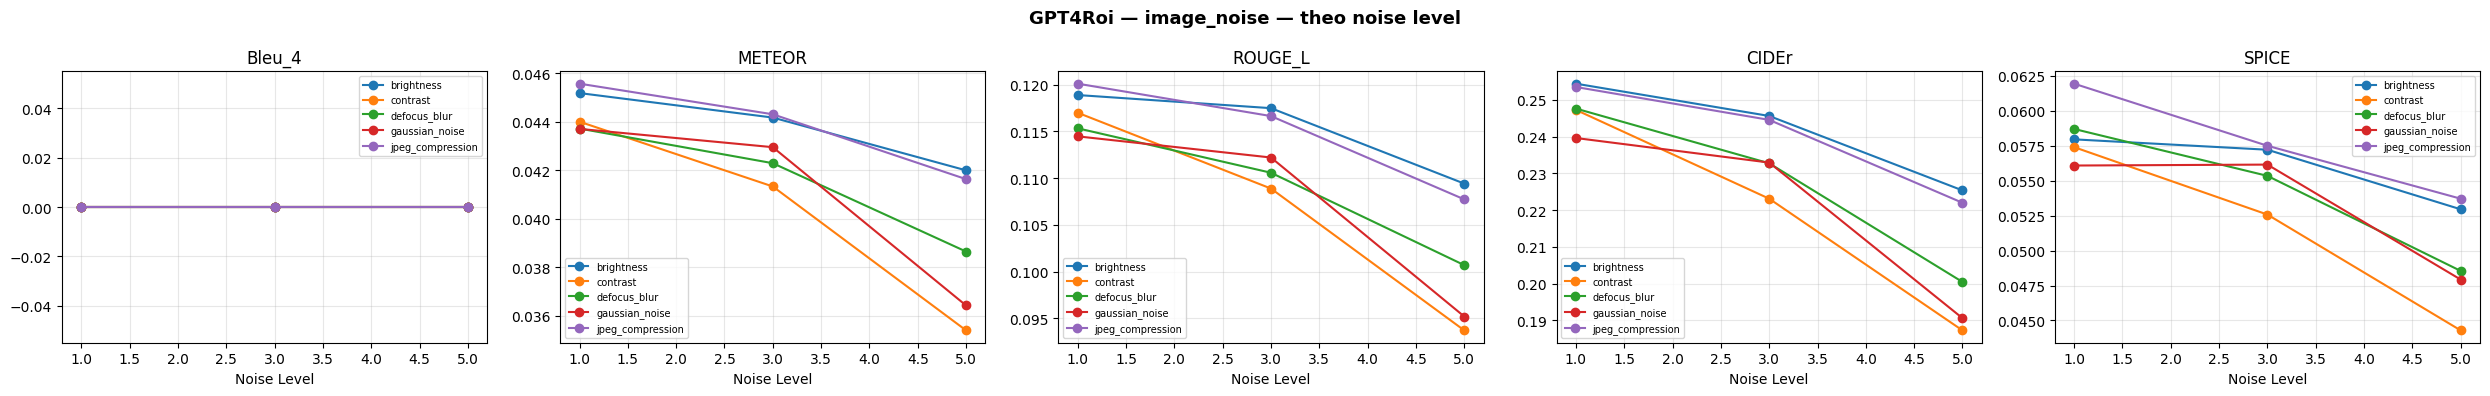

✅ Trend plot saved: /content/GPT4Roi_image_noise_trend.png


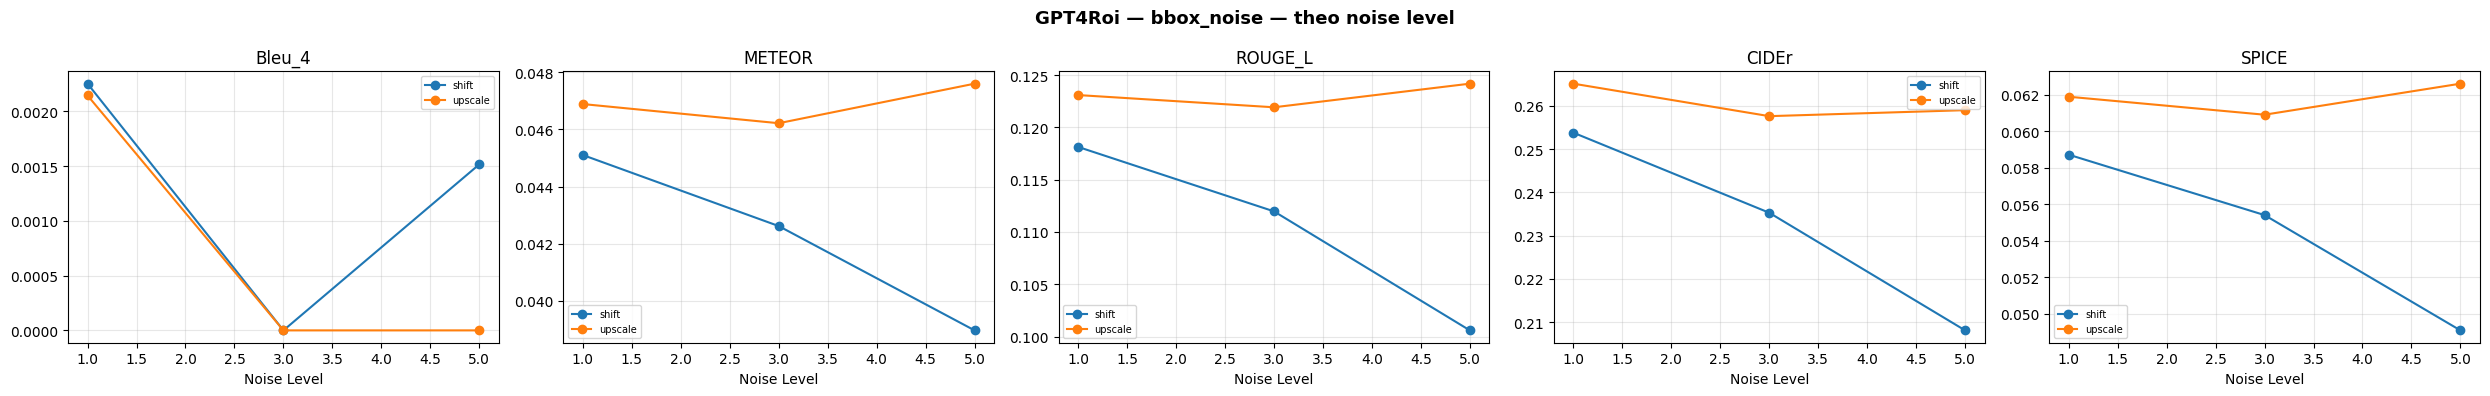

✅ Trend plot saved: /content/GPT4Roi_bbox_noise_trend.png


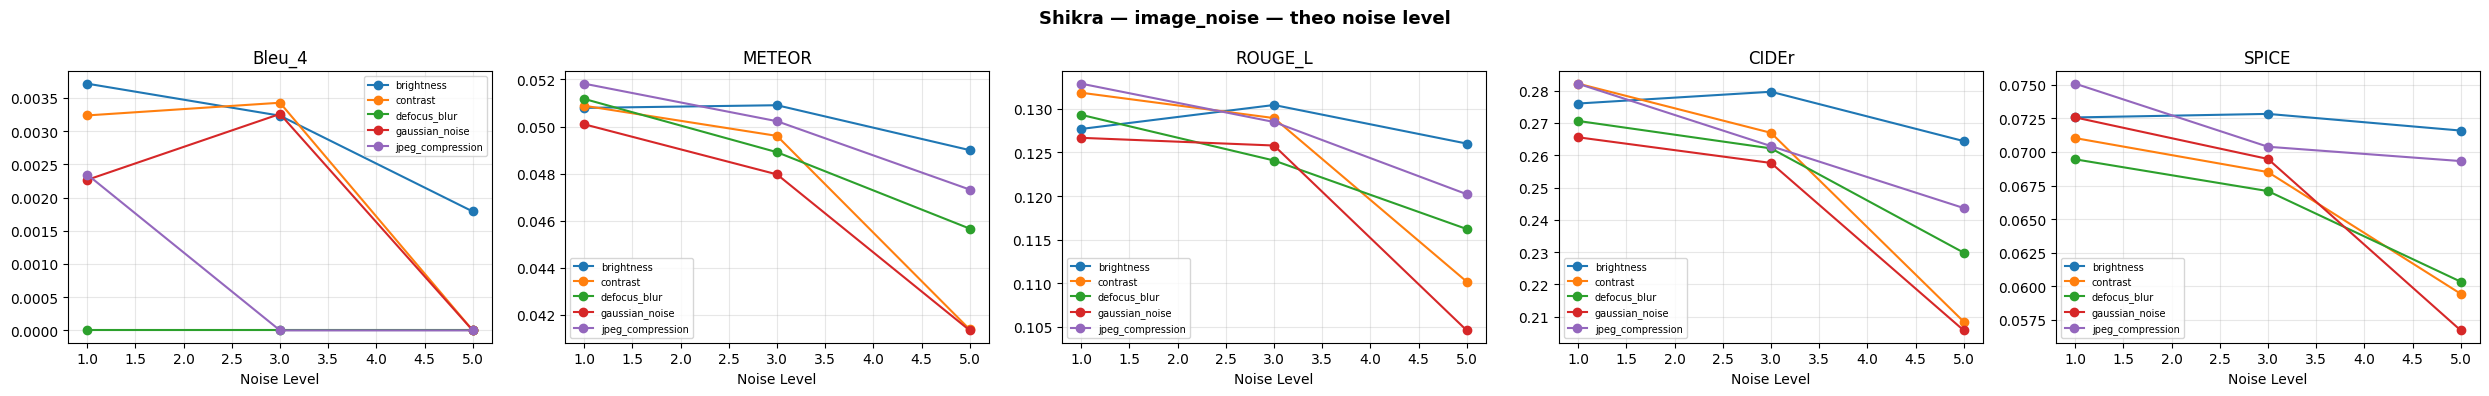

✅ Trend plot saved: /content/Shikra_image_noise_trend.png


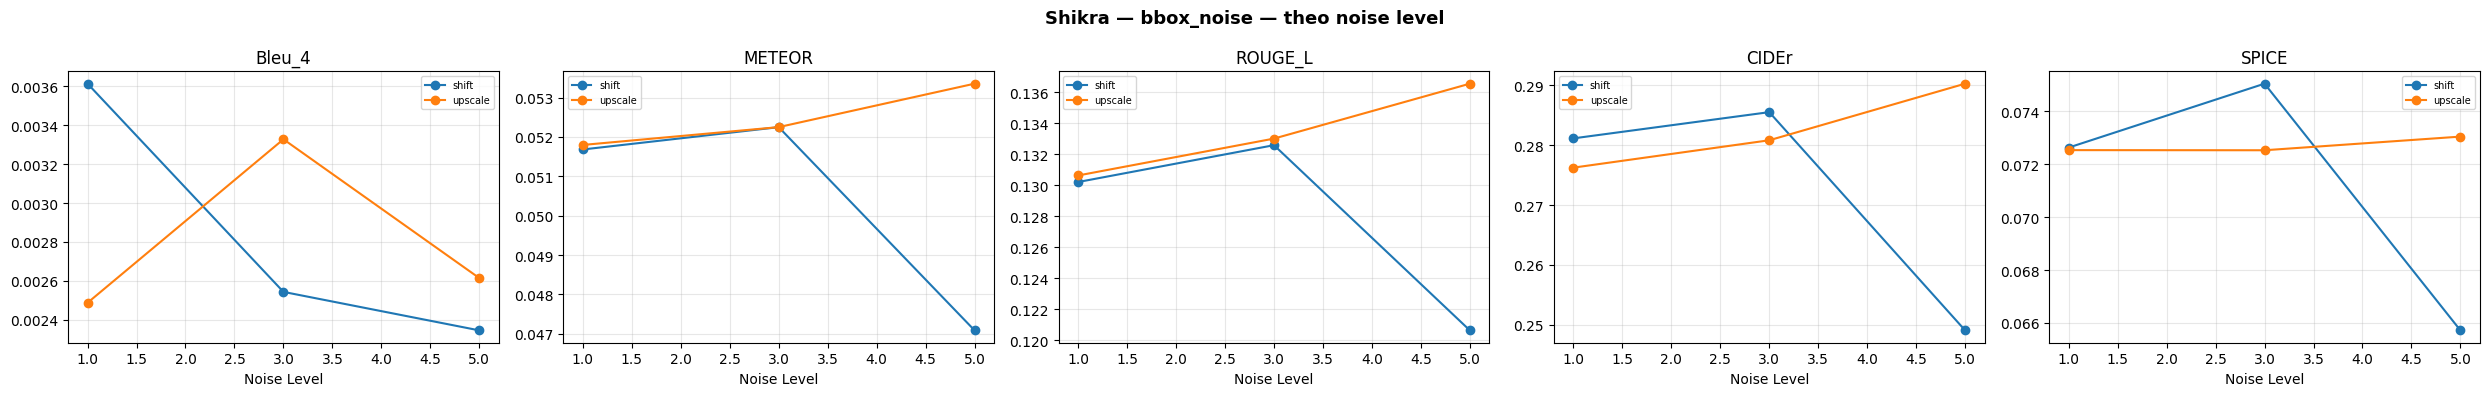

✅ Trend plot saved: /content/Shikra_bbox_noise_trend.png


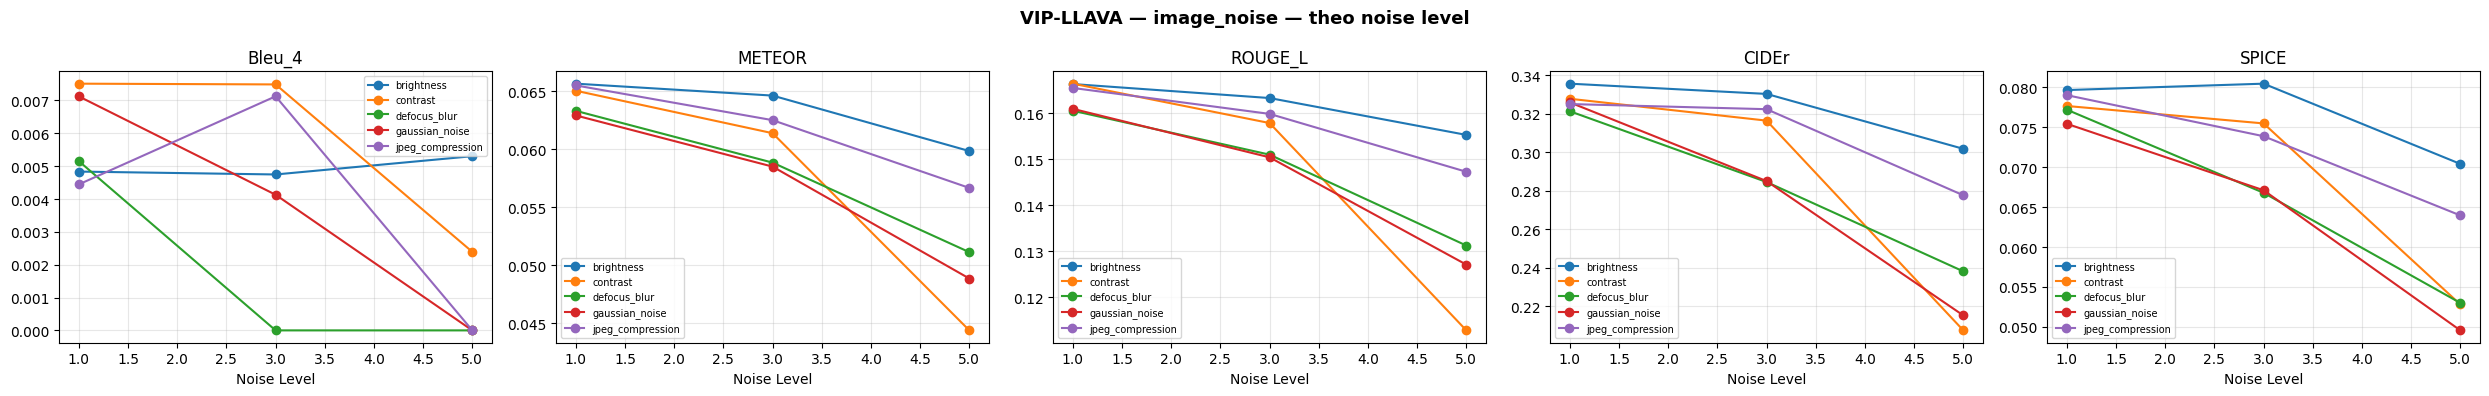

✅ Trend plot saved: /content/VIP-LLAVA_image_noise_trend.png


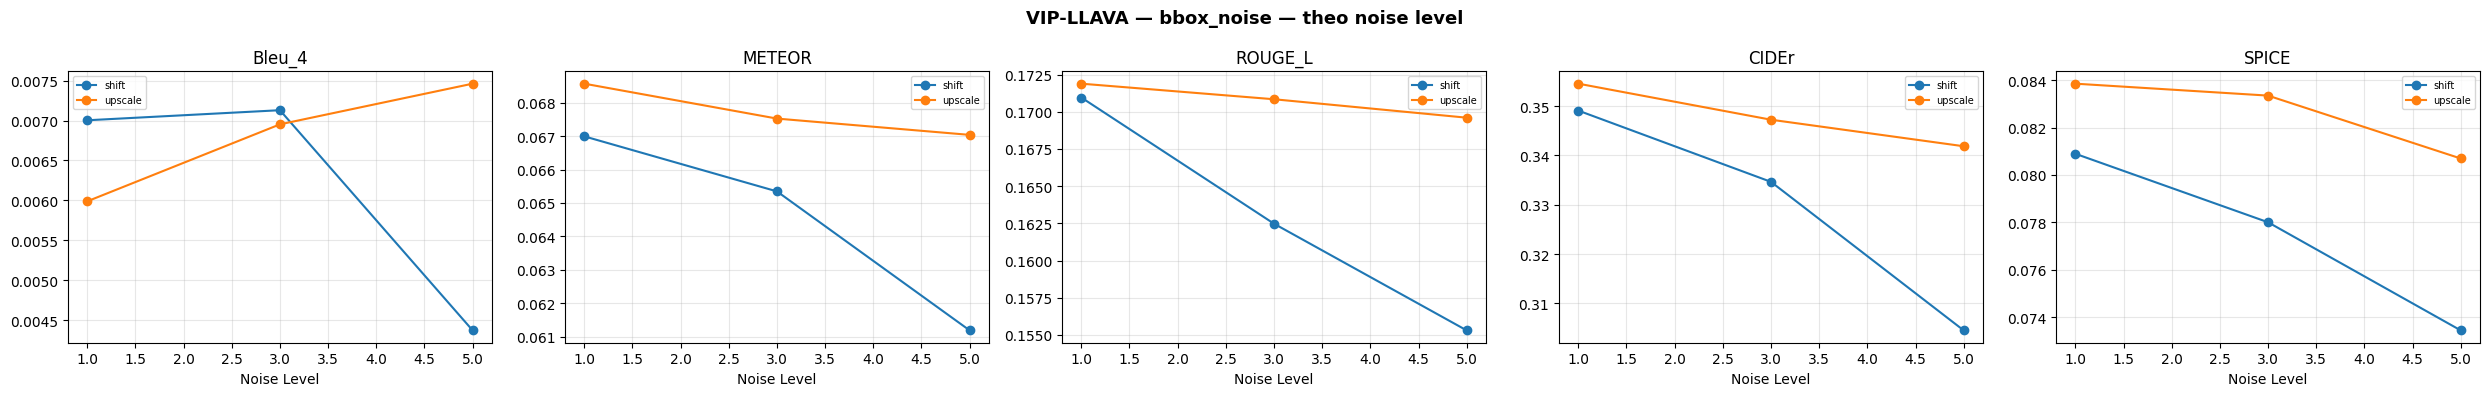

✅ Trend plot saved: /content/VIP-LLAVA_bbox_noise_trend.png


In [ ]:
for dataset_name in df_results["dataset"].unique():
    df_ds = df_results[df_results["dataset"] == dataset_name]

    for noise_cat in ["image_noise", "bbox_noise"]:
        df_cat = df_ds[df_ds["noise_category"] == noise_cat]
        if df_cat.empty:
            continue

        noise_types = df_cat["noise_type"].unique()
        fig, axes = plt.subplots(1, len(METRICS_TO_PLOT), figsize=(5 * len(METRICS_TO_PLOT), 4))
        fig.suptitle(f"{dataset_name} — {noise_cat} — theo noise level", fontsize=13, fontweight="bold")

        for ax, metric in zip(axes, METRICS_TO_PLOT):
            for nt in sorted(noise_types):
                df_nt = df_cat[df_cat["noise_type"] == nt].sort_values("noise_level")
                ax.plot(df_nt["noise_level"], df_nt[metric], marker="o", label=nt)
            ax.set_title(metric)
            ax.set_xlabel("Noise Level")
            ax.legend(fontsize=7)
            ax.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(f"/content/{dataset_name}_{noise_cat}_trend.png", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"✅ Trend plot saved: /content/{dataset_name}_{noise_cat}_trend.png")
